# Validação temporal

**Objetivo:** verificar se a validação se parece com o treino, usando a divisão definida na D8.

**Regra:** o teste não entra em nenhum cálculo deste notebook. Ele será usado uma única vez, no final do projeto.

In [1]:
from pathlib import Path
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
from divisao_temporal import calcular_cortes, dividir_por_tempo

ARQUIVO = RAIZ / "data" / "processed" / "treino.parquet"
SEGUNDOS_POR_DIA = 86_400
SEGUNDOS_POR_SEMANA = SEGUNDOS_POR_DIA * 7

base = pd.read_parquet(ARQUIVO, columns=["TransactionDT", "isFraud"])
corte_treino, corte_validacao = calcular_cortes(base["TransactionDT"])
treino, validacao, _ = dividir_por_tempo(base, corte_treino, corte_validacao)
del _, base  # o teste sai da memória antes de qualquer cálculo com isFraud

## 1. Treino e validação em números

In [2]:
pd.DataFrame(
    {
        nome: {
            "Transações": len(parte),
            "Dia inicial": round(parte["TransactionDT"].min() / SEGUNDOS_POR_DIA, 1),
            "Dia final": round(parte["TransactionDT"].max() / SEGUNDOS_POR_DIA, 1),
            "Fraudes": int(parte["isFraud"].sum()),
            "Taxa de fraude (%)": round(100 * parte["isFraud"].mean(), 2),
        }
        for nome, parte in [("Treino", treino), ("Validação", validacao)]
    }
)

,Treino,Validação
Transações,354324.00,118108.0
Dia inicial,1.00,101.2
Dia final,101.20,141.1
Fraudes,11988.00,4611.0
Taxa de fraude (%),3.38,3.9


## 2. Taxa de fraude por semana

A semana da linha pontilhada tem parte no treino e parte na validação. A última semana é parcial.

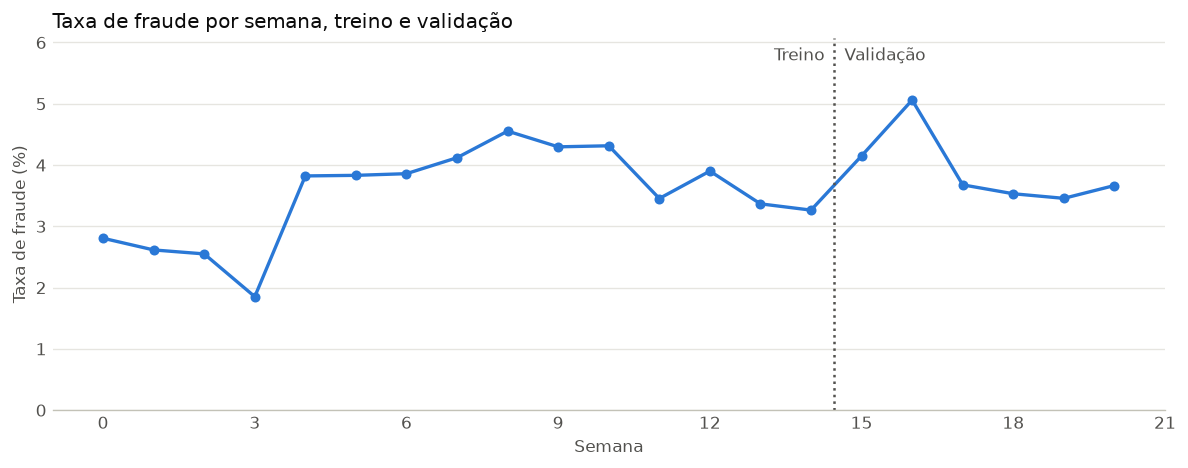

,Fraudes,Transações,Taxa (%)
Semana,,,
12,848,21734,3.90
13,935,27770,3.37
14,715,21901,3.26
15,859,20700,4.15
16,1063,21003,5.06
17,876,23824,3.68
18,693,19622,3.53
19,644,18630,3.46
20,112,3055,3.67


In [3]:
juntos = pd.concat([treino, validacao])
semana = juntos["TransactionDT"] // SEGUNDOS_POR_SEMANA
taxa_semana = juntos.groupby(semana)["isFraud"].agg(["sum", "count"])
taxa_semana.columns = ["Fraudes", "Transações"]
taxa_semana["Taxa (%)"] = 100 * taxa_semana["Fraudes"] / taxa_semana["Transações"]
taxa_semana.index.name = "Semana"

semana_corte = corte_treino / SEGUNDOS_POR_SEMANA

fig, ax = plt.subplots(figsize=(10, 4), dpi=120)
ax.plot(taxa_semana.index, taxa_semana["Taxa (%)"], marker="o", color="#2a78d6", linewidth=2, markersize=5)
ax.axvline(semana_corte, color="#52514e", linestyle=":", linewidth=1.5)
ax.set_ylim(bottom=0, top=taxa_semana["Taxa (%)"].max() * 1.2)
topo = ax.get_ylim()[1] * 0.94
ax.text(semana_corte - 0.2, topo, "Treino", ha="right", color="#52514e")
ax.text(semana_corte + 0.2, topo, "Validação", ha="left", color="#52514e")
ax.set_title("Taxa de fraude por semana, treino e validação", loc="left", color="#0b0b0b")
ax.set_xlabel("Semana", color="#52514e")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_ylabel("Taxa de fraude (%)", color="#52514e")
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors="#52514e", length=0)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
fig.tight_layout()
plt.show()

taxa_semana.loc[taxa_semana.index >= 12].round(2)

## 3. Campos vazios no treino e na validação

Lê o arquivo em lotes para economizar memória e descarta as linhas do teste de cada lote antes de contar.

In [4]:
arquivo = pq.ParquetFile(ARQUIVO)
PADROES = {"C": r"C\d+", "D": r"D\d+", "M": r"M\d+", "V": r"V\d+", "id": r"id_\d+"}
colunas_por_grupo = {
    grupo: [nome for nome in arquivo.schema_arrow.names if re.fullmatch(padrao, nome)]
    for grupo, padrao in PADROES.items()
}
todas = [coluna for grupo in colunas_por_grupo.values() for coluna in grupo]

partes = []
for lote in arquivo.iter_batches(batch_size=50_000, columns=["TransactionDT", *todas]):
    tabela = lote.to_pandas()
    tabela = tabela[tabela["TransactionDT"] <= corte_validacao]
    if tabela.empty:
        continue
    periodo = np.where(tabela["TransactionDT"] <= corte_treino, "Treino", "Validação")
    ausente = tabela[todas].isna()
    parte = pd.DataFrame({grupo: ausente[cols].sum(axis=1) for grupo, cols in colunas_por_grupo.items()})
    parte["transacoes"] = 1
    parte["com_identidade"] = (~ausente[colunas_por_grupo["id"]].all(axis=1)).astype("int8")
    partes.append(parte.groupby(periodo).sum())
    del tabela, ausente

por_periodo = pd.concat(partes).groupby(level=0).sum()

comparacao = pd.DataFrame(
    {
        grupo: 100 * por_periodo[grupo] / (por_periodo["transacoes"] * len(colunas_por_grupo[grupo]))
        for grupo in colunas_por_grupo
    }
).T
comparacao.loc["% com identidade"] = 100 * por_periodo["com_identidade"] / por_periodo["transacoes"]
comparacao["Diferença (pontos)"] = comparacao["Validação"] - comparacao["Treino"]
comparacao.index.name = "% de campos vazios"
comparacao.round(2)

,Treino,Validação,Diferença (pontos)
% de campos vazios,,,
C,0.00,0.00,0.00
D,59.99,55.83,-4.16
M,58.79,36.89,-21.90
V,42.68,43.92,1.24
id,82.77,88.29,5.52
% com identidade,27.47,19.60,-7.87


## Conclusões da validação temporal

- A divisão (D8) coloca 354.324 transações no treino, dos dias 1 a 101,2, e 118.108 na validação, dos dias 101,2 a 141,1. A validação começa estritamente depois do corte. Com isso, nenhuma transação aparece nos dois períodos, o que seria vazamento de dados.
- A taxa de fraude é maior na validação: 3,90% contra 3,38% no treino. A diferença é pequena em pontos (0,52), mas equivale a cerca de 15% a mais em proporção. Nas semanas completas da validação, a taxa vai de 3,46% a 5,06%.
- Um modelo ajustado a um período pode errar o nível das probabilidades em outro, o que precisa ser verificado na calibração.
- O grupo M é o que mais muda: os campos vazios caem de 58,79% para 36,89%, uma diferença de 21,90 pontos. O grupo id sobe de 82,77% para 88,29%, e as transações com identidade caem de 27,47% para 19,60%.
- Um modelo que aprenda padrões de ausência em M ou id pode perder desempenho fora do treino. A causa da mudança não foi investigada.
- Este notebook não diz nada sobre o teste. Continuam como limites o atraso do rótulo de fraude e as colunas V e D, que não dá para auditar quanto ao uso de informação futura.